# Auditoría y EDA de Sentimiento Silver (Claude Haiku 5.5 — 27.350 Artículos)

**Proyecto:** TFM Data Science — Predicción de Mercado Bancario (Big 6 US Banks)  
**Objetivo:** Analizar la distribución, coherencia interna, precisión frente a Ground Truth humano, correlación con cotizaciones de Yahoo Finance y eficiencia de costes de toda la capa Silver (`processed/huggingface/multisource_bancos_2010_2023.parquet`).

### Índice del Notebook
1. **Carga unificada (Local / Cloudflare R2):** Silver (`27.350`), Caché LLM (`24.900` hashes) y `yfinance` (`2010–2023`).
2. **Distribución Global del Sentimiento:** Polaridad por banco, categoría, año e histograma de convicción.
3. **Coherencia Interna y Aislamiento Multi-Ticker:** Consistencia `label` ↔ `score`, calibración de probabilidades, diferenciación entre bancos compartidos y top motivos.
4. **Precisión Escalada (`v3` + Auditoría de 50 Artículos en 3 Fragmentos Aleatorios):** Benchmark exacto sobre `143/150` etiquetas humanas y muestreo estratificado de 50 artículos nuevos.
5. **Correlación con Cotizaciones Bursátiles (`yfinance`):** Alineación de cada noticia a su sesión hábil y comparación de retornos según sentimiento (`-1 / 0 / +1`).
6. **Costes Reales y Eficiencia:** Tokens reales consumidos, coste Batch vs Realtime y ahorro por deduplicación (`cat_hash` + `input_hash`).


In [46]:
# 0. Configuración de entorno e importaciones del proyecto
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

curr = Path.cwd().resolve()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from articulos.etl_sentimientos import BATCH_IN_USD_1M, BATCH_OUT_USD_1M
from dependencies.dependencies import get_storage_repository
from shared.parquet_cache import cargar_parquet_local_o_r2
from shared.tickets import TICKETS

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.max_columns", 30)
print(f"[OK] PROJ_ROOT: {PROJ_ROOT}")


[OK] PROJ_ROOT: C:\proyectos\TFM-Master


## 1. Carga de Datos (Silver, Caché LLM y Yahoo Finance)


In [47]:
# 1.1 Cargar Silver y caché de sentimiento desde disco local (con fallback automático a R2)
SILVER_PATH = PROJ_ROOT / "data" / "processed_multisource_bancos_2010_2023.parquet"
CACHE_PATH = PROJ_ROOT / "data" / "silver_sentiment_cache.parquet"
STOCKS_PATH = PROJ_ROOT / "data" / "stocks_2010_2023.parquet"

rows_silver = await cargar_parquet_local_o_r2(
    SILVER_PATH, "processed/huggingface/multisource_bancos_2010_2023.parquet", nombre="Silver"
)
rows_cache = await cargar_parquet_local_o_r2(
    CACHE_PATH, "processed/huggingface/sentiment_cache.parquet", nombre="sentiment_cache"
)

df_silver = pd.DataFrame(rows_silver)
df_cache = pd.DataFrame(rows_cache)

df_silver["datetime"] = pd.to_datetime(df_silver["datetime"], errors="coerce")
df_silver["year"] = df_silver["datetime"].dt.year
df_silver["banco"] = df_silver["ticker"].map(lambda t: TICKETS.get(t, {}).get("short_name", t))

# 1.2 Cargar cotizaciones yfinance (Wide Parquet con DatetimeIndex) desde local o R2
if STOCKS_PATH.exists():
    df_stocks = pd.read_parquet(STOCKS_PATH)
else:
    repo = get_storage_repository()
    try:
        raw_stocks = await repo.get("raw/yfinance/stocks_2010_2023.parquet")
        STOCKS_PATH.parent.mkdir(parents=True, exist_ok=True)
        STOCKS_PATH.write_bytes(raw_stocks)
        df_stocks = pd.read_parquet(STOCKS_PATH)
    finally:
        await repo.close()

print(f"[OK] Silver cargado        : {len(df_silver):,} filas | Nulos en label: {df_silver['sentiment_label'].isna().sum()}")
print(f"[OK] Caché LLM cargada     : {len(df_cache):,} hashes únicos ({len(df_silver) - len(df_cache):,} filas deduplicadas gratis)")
print(f"[OK] Cotizaciones yfinance : {df_stocks.shape[0]:,} sesiones ({df_stocks.index.min().date()} -> {df_stocks.index.max().date()})")
df_silver.head(5)


 INFO     | 2026-11-23 14:58:25.751406 | ParquetCache | Reutilizando Silver local: [C:\proyectos\TFM-Master\data\processed_multisource_bancos_2010_2023.parquet]
 INFO     | 2026-11-23 14:58:26.143114 | ParquetCompactor | Descompactados 27,350 registros desde buffer Parquet (4,163,589 bytes).
 INFO     | 2026-11-23 14:58:26.173779 | ParquetCache | Reutilizando sentiment_cache local: [C:\proyectos\TFM-Master\data\silver_sentiment_cache.parquet]
 INFO     | 2026-11-23 14:58:26.250930 | ParquetCompactor | Descompactados 24,900 registros desde buffer Parquet (1,468,609 bytes).
[OK] Silver cargado        : 27,350 filas | Nulos en label: 0
[OK] Caché LLM cargada     : 24,900 hashes únicos (2,450 filas deduplicadas gratis)
[OK] Cotizaciones yfinance : 3,522 sesiones (2010-01-04 -> 2023-12-29)


,record_id,ticker,company_name,cik,date,datetime,has_exact_time,market_session,title,ticker_count,is_multisubject,process_text,category,confianza,is_ruido,input_hash,sentiment_label,sentiment_score,p_pos,p_neg,p_neu,sentiment_motivo,sentiment_model,sentiment_prompt_ver,year,banco
0,2bacd3e9430301bc43b2beb1,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-04 12:01:00,2010-01-04 12:01:00-05:00,True,intraday,"GS: December Trading Volume Slipped, Says Cred...",5,True,Shares of Goldman Sachs (GS) are rising with f...,earnings,48.47,False,c5df040d66e0c73792e44aa5ec8cc7282cbea1cb5020cf...,0,-0.10,0.20,0.30,0.5,"Analyst flags trading volume drop, though shar...",claude-haiku-5-5,v1_en,2010,Goldman Sachs
1,42cd678dc4891b8eb9a31bc9,MS,Morgan Stanley,CIK0000895421,2010-01-04 17:23:00,2010-01-04 17:23:00-05:00,True,afterhours,"Morgan Stanley: Credit Suisse, UBS Up to ""Buy,...",5,True,"As mentioned earlier, Morgan Stanley (MS) rece...",m&a,45.47,False,fb6ad62d5e5a2a43a961344342fdbdb864cab8803938d0...,1,0.70,0.85,0.05,0.1,Credit Suisse and UBS upgraded Morgan Stanley ...,claude-haiku-5-5,v1_en,2010,Morgan Stanley
2,c1a93dc7d57b8c2e2e186a05,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-05 11:20:00,2010-01-05 11:20:00-05:00,True,intraday,Analyst cuts broker estimates on trading slowdown,2,True,Pali Research scales back fourth-quarter profi...,earnings,48.80,False,e44472b8fe08029abe8f984fb9861839cd642ce4fee056...,-1,-0.50,0.05,0.75,0.2,Analyst cut Q4 profit estimates on trading slo...,claude-haiku-5-5,v1_en,2010,Goldman Sachs
3,e3cbf55e0871305afc44a1d2,MS,Morgan Stanley,CIK0000895421,2010-01-05 11:20:00,2010-01-05 11:20:00-05:00,True,intraday,Analyst cuts broker estimates on trading slowdown,2,True,Pali Research scales back fourth-quarter profi...,earnings,48.80,False,982b80549ec98e66207813f0eaec76903c770b10c0f76e...,-1,-0.50,0.05,0.75,0.2,Analyst cut Q4 profit estimates on trading slo...,claude-haiku-5-5,v1_en,2010,Morgan Stanley
4,819c7467fb19977f383f1089,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-05 11:29:00,2010-01-05 11:29:00-05:00,True,intraday,GS: Pali Cuts Estimates on Trading,5,True,"Financials are broadly higher today, with Gold...",earnings,45.49,False,5174e63b170e2bf9a10de979977b9e11f27569488b02c2...,0,-0.15,0.25,0.35,0.4,Pali lowered December-quarter estimates; share...,claude-haiku-5-5,v1_en,2010,Goldman Sachs


## 2. Distribución Global del Sentimiento (27.350 Artículos)


=== DISTRIBUCIÓN GLOBAL DE SENTIMIENTO ===


,Etiqueta,Artículos,Porcentaje (%)
0,Negativo (-1),7193,26.30
1,Neutral (0),12613,46.12
2,Positivo (+1),7544,27.58



=== DISTRIBUCIÓN POR BANCO (% filas) ===


,Negativo (-1),Neutral (0),Positivo (+1),Total_Artículos,Score_Medio
banco,,,,,
Wells Fargo,31.2,43.2,25.6,5388,-0.039
Morgan Stanley,22.5,50.4,27.1,5354,0.032
Goldman Sachs,23.8,53.6,22.6,5133,-0.009
JPMorgan Chase,30.1,40.9,29.0,4315,-0.006
Citigroup,23.0,46.6,30.4,4299,0.039
Bank of America,27.9,37.3,34.9,2861,0.043



=== DISTRIBUCIÓN POR CATEGORÍA SEMÁNTICA (% filas) ===


,Negativo (-1),Neutral (0),Positivo (+1),Total_Artículos,Score_Medio
category,,,,,
earnings,25.4,34.0,40.6,9968,0.091
macro,21.1,53.1,25.8,2823,0.018
m&a,19.8,57.3,22.9,9995,0.012
governance,16.6,71.4,12.0,853,-0.019
credit,44.7,40.4,14.9,767,-0.153
legal,54.2,36.7,9.1,2944,-0.262


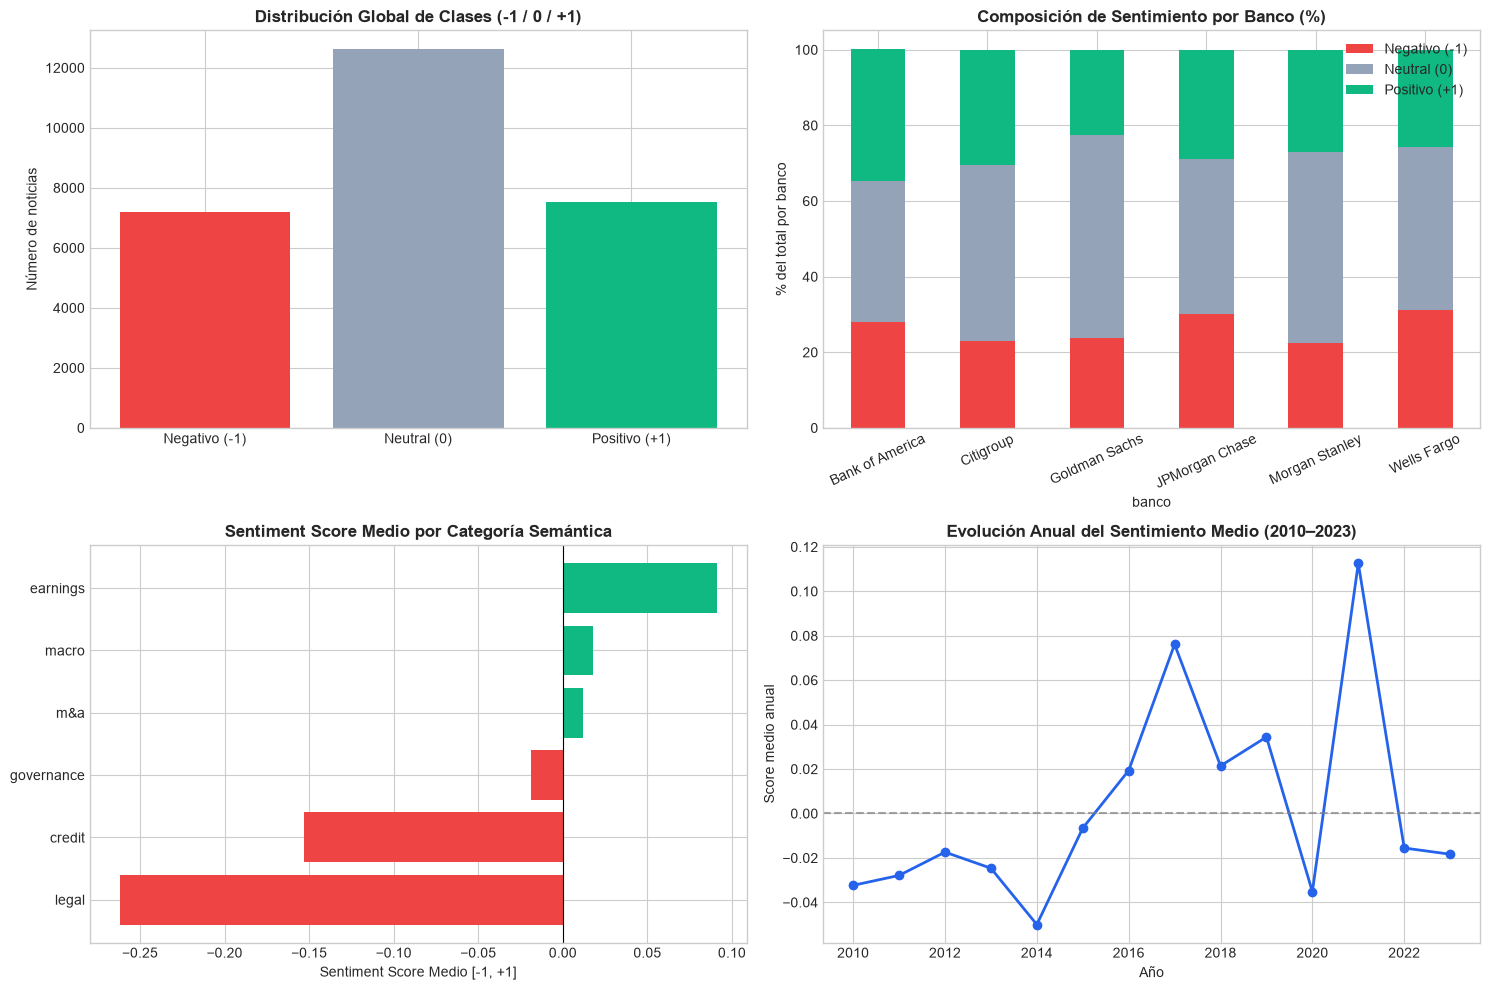

In [48]:
# 2.1 Resumen global y por dimensiones clave
etiquetas_txt = {-1: "Negativo (-1)", 0: "Neutral (0)", 1: "Positivo (+1)"}
dist_global = df_silver["sentiment_label"].value_counts().sort_index()
res_global = pd.DataFrame({
    "Etiqueta": [etiquetas_txt[k] for k in dist_global.index],
    "Artículos": dist_global.values,
    "Porcentaje (%)": (100 * dist_global.values / len(df_silver)).round(2),
})
print("=== DISTRIBUCIÓN GLOBAL DE SENTIMIENTO ===")
display(res_global)

print("\n=== DISTRIBUCIÓN POR BANCO (% filas) ===")
tab_banco = pd.crosstab(df_silver["banco"], df_silver["sentiment_label"], normalize="index").mul(100).round(1)
tab_banco.columns = [etiquetas_txt[c] for c in tab_banco.columns]
tab_banco["Total_Artículos"] = df_silver.groupby("banco").size()
tab_banco["Score_Medio"] = df_silver.groupby("banco")["sentiment_score"].mean().round(3)
display(tab_banco.sort_values("Total_Artículos", ascending=False))

print("\n=== DISTRIBUCIÓN POR CATEGORÍA SEMÁNTICA (% filas) ===")
tab_cat = pd.crosstab(df_silver["category"], df_silver["sentiment_label"], normalize="index").mul(100).round(1)
tab_cat.columns = [etiquetas_txt[c] for c in tab_cat.columns]
tab_cat["Total_Artículos"] = df_silver.groupby("category").size()
tab_cat["Score_Medio"] = df_silver.groupby("category")["sentiment_score"].mean().round(3)
display(tab_cat.sort_values("Score_Medio", ascending=False))

# 2.2 Gráficos descriptivos
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
colores = ["#ef4444", "#94a3b8", "#10b981"]

# Panel A: Conteo global
axes[0, 0].bar([etiquetas_txt[k] for k in dist_global.index], dist_global.values, color=colores)
axes[0, 0].set_title("Distribución Global de Clases (-1 / 0 / +1)", fontweight="bold")
axes[0, 0].set_ylabel("Número de noticias")

# Panel B: % por banco
tab_banco[["Negativo (-1)", "Neutral (0)", "Positivo (+1)"]].plot(
    kind="bar", stacked=True, color=colores, ax=axes[0, 1]
)
axes[0, 1].set_title("Composición de Sentimiento por Banco (%)", fontweight="bold")
axes[0, 1].set_ylabel("% del total por banco")
axes[0, 1].tick_params(axis="x", rotation=25)

# Panel C: Score medio por categoría
cat_ord = tab_cat["Score_Medio"].sort_values()
cat_colors = ["#ef4444" if v < 0 else "#10b981" for v in cat_ord.values]
axes[1, 0].barh(cat_ord.index, cat_ord.values, color=cat_colors)
axes[1, 0].axvline(0, color="black", linewidth=0.8)
axes[1, 0].set_title("Sentiment Score Medio por Categoría Semántica", fontweight="bold")
axes[1, 0].set_xlabel("Sentiment Score Medio [-1, +1]")

# Panel D: Evolución anual del score medio y volumen
anual = df_silver.groupby("year").agg(score_medio=("sentiment_score", "mean"), n=("record_id", "count"))
axes[1, 1].plot(anual.index, anual["score_medio"], marker="o", color="#2563eb", linewidth=2)
axes[1, 1].axhline(0, color="gray", linestyle="--", alpha=0.7)
axes[1, 1].set_title("Evolución Anual del Sentimiento Medio (2010–2023)", fontweight="bold")
axes[1, 1].set_ylabel("Score medio anual")
axes[1, 1].set_xlabel("Año")

plt.tight_layout()
plt.show()


## 3. Coherencia Interna, Aislamiento Multi-Ticker y Top Motivos


In [49]:
# 3.1 Chequeos de coherencia matemática y lógica en las 27.350 filas
p_sum = df_silver["p_pos"] + df_silver["p_neg"] + df_silver["p_neu"]
err_signo_pos = ((df_silver["sentiment_label"] == 1) & (df_silver["sentiment_score"] <= 0)).sum()
err_signo_neg = ((df_silver["sentiment_label"] == -1) & (df_silver["sentiment_score"] >= 0)).sum()
err_prob = (p_sum.sub(1.0).abs() > 0.05).sum()

print("=== CHEQUEO DE COHERENCIA ESTRUCTURAL (N = 27.350) ===")
print(f"- Etiqueta +1 con score <= 0          : {err_signo_pos} ({100*err_signo_pos/len(df_silver):.2f}%)")
print(f"- Etiqueta -1 con score >= 0          : {err_signo_neg} ({100*err_signo_neg/len(df_silver):.2f}%)")
print(f"- Suma probabilidades |sum(p)-1|>0.05 : {err_prob} ({100*err_prob/len(df_silver):.2f}%) | Media sum(p)={p_sum.mean():.4f}")

# 3.2 Aislamiento en noticias multi-ticker (mismo titular y fecha evaluados para >=2 bancos)
grupos_multi = df_silver.groupby(["date", "title"]).filter(lambda g: g["ticker"].nunique() >= 2)
stats_multi = (
    grupos_multi.groupby(["date", "title"])
    .agg(n_bancos=("ticker", "nunique"), n_labels_distintas=("sentiment_label", "nunique"), std_score=("sentiment_score", "std"))
)
pct_diferenciados = 100 * (stats_multi["n_labels_distintas"] > 1).mean() if len(stats_multi) else 0.0
print(f"\n=== AISLAMIENTO MULTI-TICKER ===")
print(f"- Artículos compartidos (>=2 bancos)     : {len(stats_multi):,} noticias ({len(grupos_multi):,} registros Silver)")
print(f"- Noticias donde asigna distinto label   : {(stats_multi['n_labels_distintas'] > 1).sum():,} ({pct_diferenciados:.1f}%)")

# 3.3 Top 10 motivos más frecuentes en Positivo (+1) y Negativo (-1)
print("\n=== TOP 10 MOTIVOS POSITIVOS (+1) ===")
display(df_silver.loc[df_silver["sentiment_label"] == 1, "sentiment_motivo"].value_counts().head(10).to_frame("Frecuencia"))

print("\n=== TOP 10 MOTIVOS NEGATIVOS (-1) ===")
display(df_silver.loc[df_silver["sentiment_label"] == -1, "sentiment_motivo"].value_counts().head(10).to_frame("Frecuencia"))


=== CHEQUEO DE COHERENCIA ESTRUCTURAL (N = 27.350) ===
- Etiqueta +1 con score <= 0          : 1 (0.00%)
- Etiqueta -1 con score >= 0          : 0 (0.00%)
- Suma probabilidades |sum(p)-1|>0.05 : 790 (2.89%) | Media sum(p)=0.9938

=== AISLAMIENTO MULTI-TICKER ===
- Artículos compartidos (>=2 bancos)     : 3,684 noticias (9,239 registros Silver)
- Noticias donde asigna distinto label   : 900 (24.4%)

=== TOP 10 MOTIVOS POSITIVOS (+1) ===


,Frecuencia
sentiment_motivo,
Morgan Stanley shares trading higher premarket,12
Q1 EPS and sales beat consensus estimates,10
Q2 EPS and revenue beat consensus estimates,9
Context states Citi beat Q2 earnings estimates by 5%,9
Citi Q4 2021 EPS $1.46 beat $1.39 consensus,8
Analyst raises price target despite Hold rating,6
Analyst raises price target on Morgan Stanley,6
WFC Q4 2016 earnings surprised positively by about 3%,6
Text cites WFC Q1 earnings positive surprise of 3.1%,6



=== TOP 10 MOTIVOS NEGATIVOS (-1) ===


,Frecuencia
sentiment_motivo,
"Premarket move lower for BAC, minor negative price action",12
"MS trading lower premarket, stock drop",8
Technical update signals Morgan Stanley stock declining,8
Analyst downgrade of BAC to Neutral,8
ok,6
Regulator warns higher borrowing costs for big banks,5
"Bank stocks retreated on stress-test disclosure dispute, sector-wide drop",5
Headline suggests poor stress test ranking; no body provided,5
Resubmitted capital plan lowering planned shareholder distributions,5


## 4. Precisión Escalada: Ground Truth (`v3`) + Muestra de 50 Artículos en 3 Bloques Aleatorios

Evaluamos en dos niveles:
1. **Nivel 1 (Exacto ya etiquetado):** Cruce de `silver` con las `150` etiquetas humanas de `scratch/finbert_pilot_v3_revision_manual.csv` (incluyendo comparación directa frente a FinBERT y ABSA DeBERTa).
2. **Nivel 2 (Muestreo aleatorio fuera del GT — 50 artículos en 3 bloques):** Extraemos `50` noticias nuevas fuera del GT previo repartidas en 3 bloques estratificados (`17 Positivos`, `17 Neutrales`, `16 Negativos`) a `scratch/silver_audit_50_muestra.csv`. Cuando rellenes `etiqueta_humana` en ese CSV y re-ejecutes la celda evaluadora, calculará el Accuracy real escalado y su intervalo de confianza al 95%.


Artículos GT emparejados en Silver: 143 / 150 (los 7 restantes fueron filtrados por is_ruido=True)
Claude Haiku 5.5 -> Accuracy: 88.8% | F1-Macro: 0.884 | Inversiones Graves (+1<->-1): 1

Classification Report:
               precision    recall  f1-score   support

Negativo (-1)      0.913     0.840     0.875        25
  Neutral (0)      0.893     0.905     0.899        74
Positivo (+1)      0.867     0.886     0.876        44

     accuracy                          0.888       143
    macro avg      0.891     0.877     0.884       143
 weighted avg      0.889     0.888     0.888       143



,Modelo,Accuracy,F1-Macro,Inversiones Graves
0,Claude Haiku 5.5 (Silver Producción),0.888,0.884,1
1,FinBERT (RE_ADAPTATIVA),0.601,0.594,13
2,ABSA DeBERTa Base,0.643,0.655,4


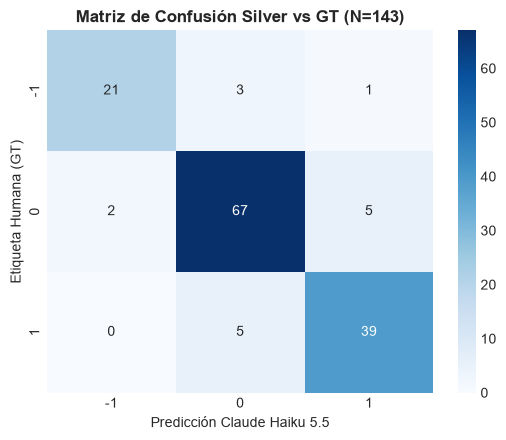

In [50]:
# 4.1 Benchmark exacto frente a Ground Truth humano (finbert_pilot_v3_revision_manual.csv)
CSV_GT = PROJ_ROOT / "scratch" / "finbert_pilot_v3_revision_manual.csv"
df_gt = pd.read_csv(CSV_GT)

m_gt = df_gt.merge(
    df_silver.drop_duplicates(subset=["ticker", "title"]),
    left_on=["ticker", "titular"],
    right_on=["ticker", "title"],
    how="inner",
)
y_true = m_gt["etiqueta_manual"].astype(int)
y_claude = m_gt["sentiment_label"].astype(int)

acc_claude = accuracy_score(y_true, y_claude)
f1_claude = f1_score(y_true, y_claude, average="macro")
inv_claude = int((((y_true == 1) & (y_claude == -1)) | ((y_true == -1) & (y_claude == 1))).sum())

print(f"Artículos GT emparejados en Silver: {len(m_gt)} / {len(df_gt)} (los {len(df_gt) - len(m_gt)} restantes fueron filtrados por is_ruido=True)")
print(f"Claude Haiku 5.5 -> Accuracy: {acc_claude:.1%} | F1-Macro: {f1_claude:.3f} | Inversiones Graves (+1<->-1): {inv_claude}")
print("\nClassification Report:")
print(classification_report(y_true, y_claude, labels=[-1, 0, 1], target_names=["Negativo (-1)", "Neutral (0)", "Positivo (+1)"], digits=3))

# Comparativa directa vs FinBERT y ABSA sobre exactamente los mismos 143 artículos
disc = lambda s: s.apply(lambda x: 1 if x > 0.15 else (-1 if x < -0.15 else 0))
comp_rows = [{"Modelo": "Claude Haiku 5.5 (Silver Producción)", "Accuracy": acc_claude, "F1-Macro": f1_claude, "Inversiones Graves": inv_claude}]
for nom, col in [("FinBERT (RE_ADAPTATIVA)", "RE_ADAPTATIVA_sent"), ("ABSA DeBERTa Base", "ABSA_DEBERTA_BASE_sent")]:
    if col in m_gt.columns:
        yp = disc(m_gt[col])
        comp_rows.append({
            "Modelo": nom,
            "Accuracy": accuracy_score(y_true, yp),
            "F1-Macro": f1_score(y_true, yp, average="macro"),
            "Inversiones Graves": int((((y_true == 1) & (yp == -1)) | ((y_true == -1) & (yp == 1))).sum()),
        })
display(pd.DataFrame(comp_rows).round(3))

# Matriz de confusión visual
cm = confusion_matrix(y_true, y_claude, labels=[-1, 0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[-1, 0, 1], yticklabels=[-1, 0, 1], ax=ax)
ax.set_xlabel("Predicción Claude Haiku 5.5")
ax.set_ylabel("Etiqueta Humana (GT)")
ax.set_title(f"Matriz de Confusión Silver vs GT (N={len(m_gt)})", fontweight="bold")
plt.tight_layout()
plt.show()


In [51]:
# 4.2 Generación de muestra aleatoria estratificada de 50 artículos en 3 bloques (fuera del GT previo)
CSV_AUDIT_50 = PROJ_ROOT / "scratch" / "silver_audit_50_muestra.csv"

gt_keys = set(zip(df_gt["ticker"], df_gt["titular"]))
pool = df_silver[~df_silver.apply(lambda r: (r["ticker"], r["title"]) in gt_keys, axis=1)].copy()

bloques_cfg = [
    ("Bloque_1_Positivo", 1, 17),
    ("Bloque_2_Neutral", 0, 17),
    ("Bloque_3_Negativo", -1, 16),
]
partes = []
for nombre_bloque, lbl, n_take in bloques_cfg:
    sub = pool[pool["sentiment_label"] == lbl].sample(n=n_take, random_state=42).copy()
    sub.insert(0, "bloque", nombre_bloque)
    partes.append(sub)

df_50 = pd.concat(partes, ignore_index=True)[[
    "bloque", "record_id", "ticker", "banco", "category", "date", "title",
    "process_text", "sentiment_label", "sentiment_score", "sentiment_motivo"
]].rename(columns={"sentiment_label": "claude_label", "sentiment_score": "claude_score", "sentiment_motivo": "claude_motivo"})
df_50["etiqueta_humana"] = ""

# Proteger anotaciones previas si el CSV ya fue etiquetado manualmente
if CSV_AUDIT_50.exists():
    prev = pd.read_csv(CSV_AUDIT_50)
    if "etiqueta_humana" in prev.columns and "record_id" in prev.columns:
        prev_map = prev.set_index("record_id")["etiqueta_humana"].to_dict()
        df_50["etiqueta_humana"] = [
            "" if pd.isna(prev_map.get(rid)) else prev_map.get(rid) for rid in df_50["record_id"]
        ]
else:
    CSV_AUDIT_50.parent.mkdir(parents=True, exist_ok=True)
df_50.to_csv(CSV_AUDIT_50, index=False, encoding="utf-8-sig")
print(f"[OK] Muestra de 50 artículos guardada en: {CSV_AUDIT_50}")
print("Distribución por bloque:")
display(df_50.groupby("bloque")["claude_label"].value_counts().to_frame("Conteo"))

# Evaluador automático (se activa al rellenar `etiqueta_humana` con -1, 0 o 1 en el CSV)
y_hum = pd.to_numeric(df_50["etiqueta_humana"], errors="coerce")
eval_50 = df_50[y_hum.isin([-1, 0, 1])].copy()
if len(eval_50) > 0:
    yt50 = pd.to_numeric(eval_50["etiqueta_humana"]).astype(int)
    yp50 = eval_50["claude_label"].astype(int)
    p = accuracy_score(yt50, yp50)
    z = 1.96
    n50 = len(eval_50)
    denom = 1 + z**2 / n50
    centro = (p + z**2 / (2 * n50)) / denom
    radio = (z * np.sqrt((p * (1 - p) + z**2 / (4 * n50)) / n50)) / denom
    print(f"\n[RESULTADO AUDITORÍA 50] Evaluados: {n50}/50 | Accuracy: {p:.1%} | IC 95% Wilson: [{centro - radio:.1%}, {centro + radio:.1%}]")
    display(eval_50.groupby("bloque").apply(lambda g: (pd.to_numeric(g["etiqueta_humana"]) == g["claude_label"]).mean()).round(3).to_frame("Accuracy_Bloque"))
else:
    print("\n[PENDIENTE] Rellena la columna `etiqueta_humana` (-1, 0 o 1) en scratch/silver_audit_50_muestra.csv y re-ejecuta esta celda.")


[OK] Muestra de 50 artículos guardada en: C:\proyectos\TFM-Master\scratch\silver_audit_50_muestra.csv
Distribución por bloque:


,,Conteo
bloque,claude_label,
Bloque_1_Positivo,1,17
Bloque_2_Neutral,0,17
Bloque_3_Negativo,-1,16



[PENDIENTE] Rellena la columna `etiqueta_humana` (-1, 0 o 1) en scratch/silver_audit_50_muestra.csv y re-ejecuta esta celda.


## 5. Correlación con Cotizaciones Reales (`yfinance` 2010–2023)

Para comprobar si el sentimiento de Claude va alineado con el movimiento real de la bolsa sin sesgos:
1. Cada noticia se asigna al **primer día en que la bolsa está abierta** desde su fecha de publicación (por ejemplo, una noticia de sábado se asigna a la sesión del lunes mediante `merge_asof(..., direction="forward")`).
2. Calculamos dos retornos por banco y día:
   - **`ret_sesion` (`(Close - Open) / Open`)**: variación durante esa jornada bursátil.
   - **`ret_diario` (`Close_t / Close_{t-1} - 1`)**: variación frente al cierre anterior.
   - **`ret_sig` (`ret_diario` del día hábil `t+1`)**: reacción al día siguiente de cotización.
3. Comparamos el retorno medio cuando el sentimiento es **Positivo (`+1`)** frente a **Negativo (`-1`)** y medimos la correlación de Pearson y Spearman.


[OK] Cruce completado: 27,349 noticias -> 10,734 pares únicos (banco x sesión bursátil).

=== RETORNO BURSÁTIL MEDIO SEGÚN SENTIMIENTO DIARIO (yfinance) ===


,Sesiones,Ret_Sesión_Media (%),Ret_Diario_Media (%),Ret_t+1_Media (%)
Negativo (-1),3259,-0.304,-0.738,0.052
Neutral (0),4348,0.010,0.077,0.062
Positivo (+1),3127,0.290,0.843,0.005


Spread diario (Positivo - Negativo): +158.1 bps | Pearson=0.2780 | Spearman=0.2750


,Sesiones,Pearson_Diario,Spearman_Diario,Ret_Pos (%),Ret_Neg (%)
banco,,,,,
Bank of America,1393.0,0.3774,0.3844,1.0394,-1.2595
Citigroup,1708.0,0.2556,0.2671,0.8283,-0.8232
Goldman Sachs,1931.0,0.2821,0.2568,0.7892,-0.6692
JPMorgan Chase,1764.0,0.3132,0.3065,0.9068,-0.7573
Morgan Stanley,2001.0,0.2211,0.2130,0.7723,-0.5095
Wells Fargo,1937.0,0.2314,0.2441,0.7441,-0.5641



=== IMPACTO SEGÚN FRANJA HORARIA DE NUEVA YORK (Positivo - Negativo en bps) ===


,Franja Horaria (ET),Noticias,Sesiones,Spread Gap Apertura t (bps),Spread Retorno Día t (bps),Spread Gap Mañana t+1 (bps),Spread Retorno Mañana t+1 (bps),Pearson Día t
0,0. Sin hora real (date_only),15900,6558,67.9,117.8,4.8,14.8,0.2027
1,1. Premarket (<09:30 ET),3408,2170,196.7,188.2,-27.2,-35.1,0.2854
2,2. Intradía (09:30-16:00 ET),5930,4184,151.2,269.7,-9.4,-21.1,0.4531
3,3. Post-cierre (>=16:00 ET),2111,1683,150.9,365.7,15.9,16.2,0.5010


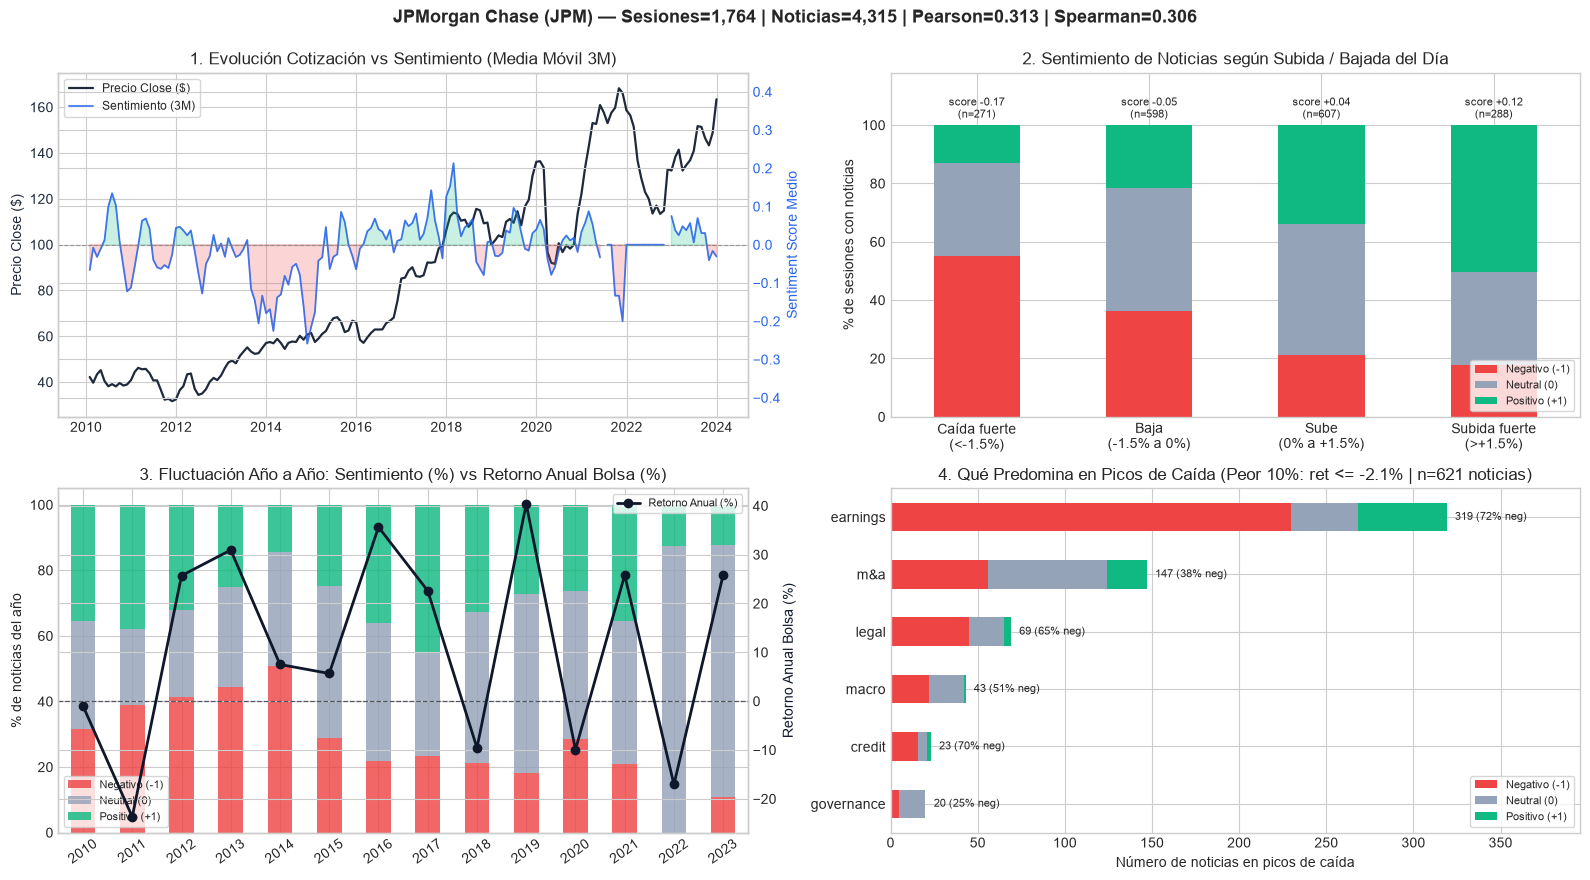

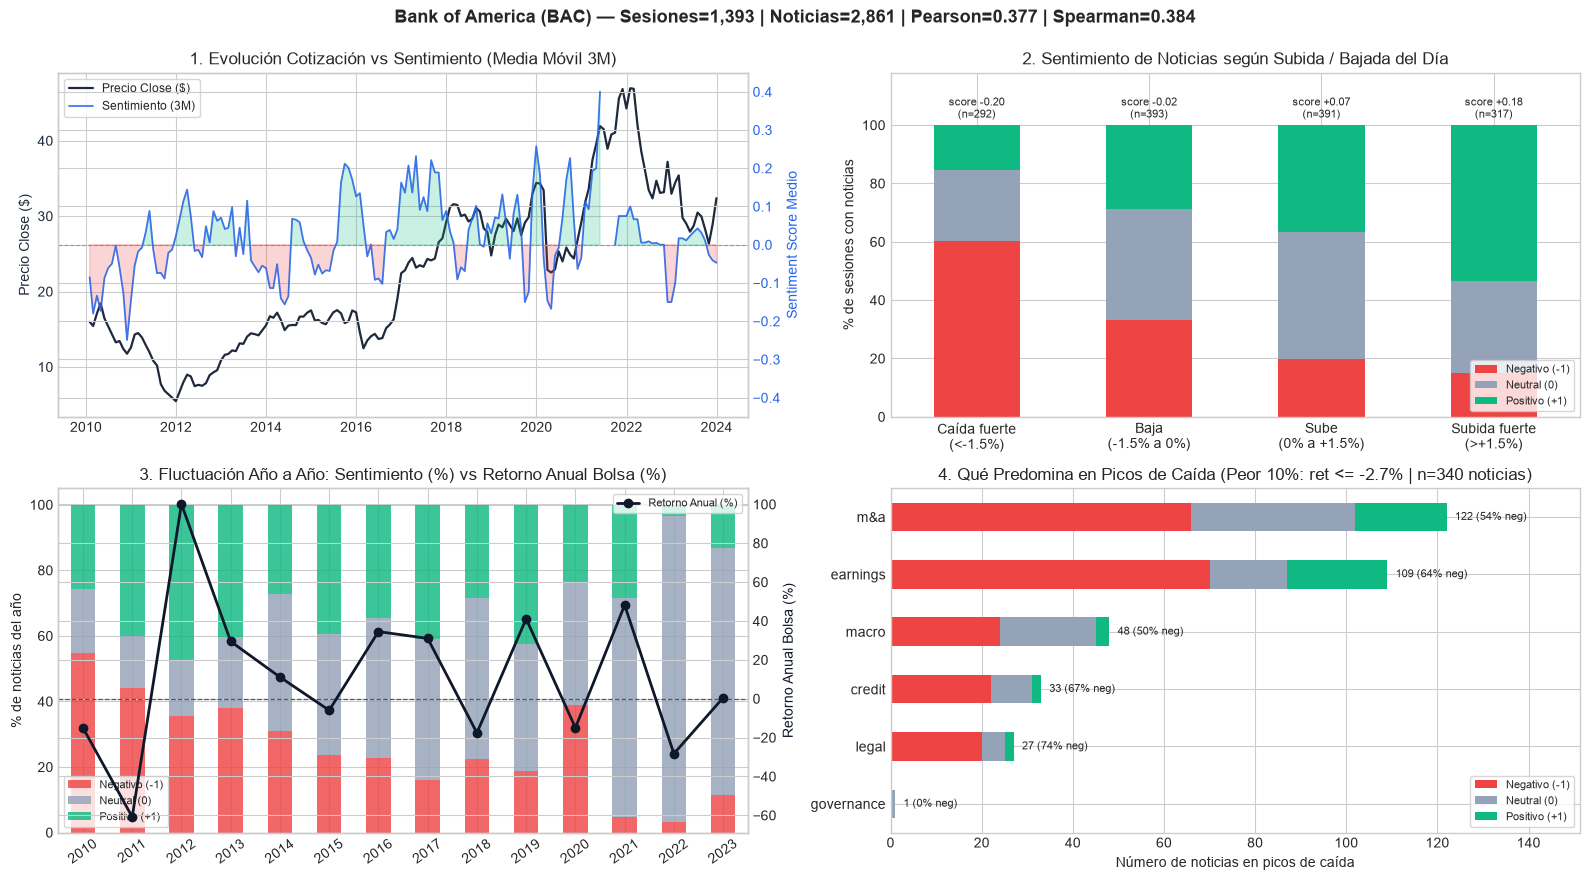

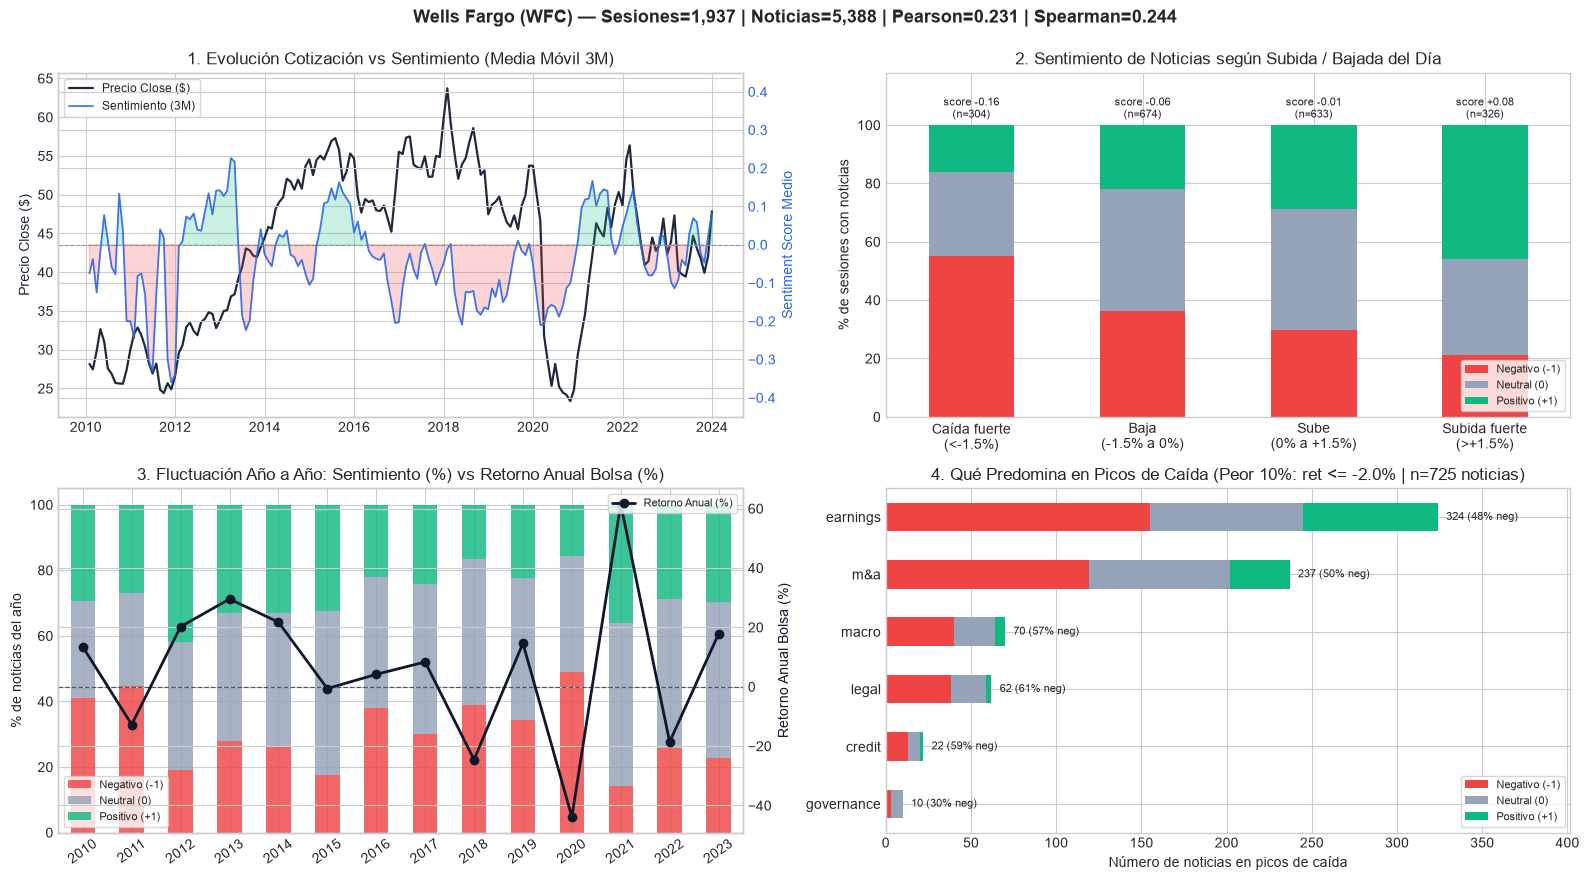

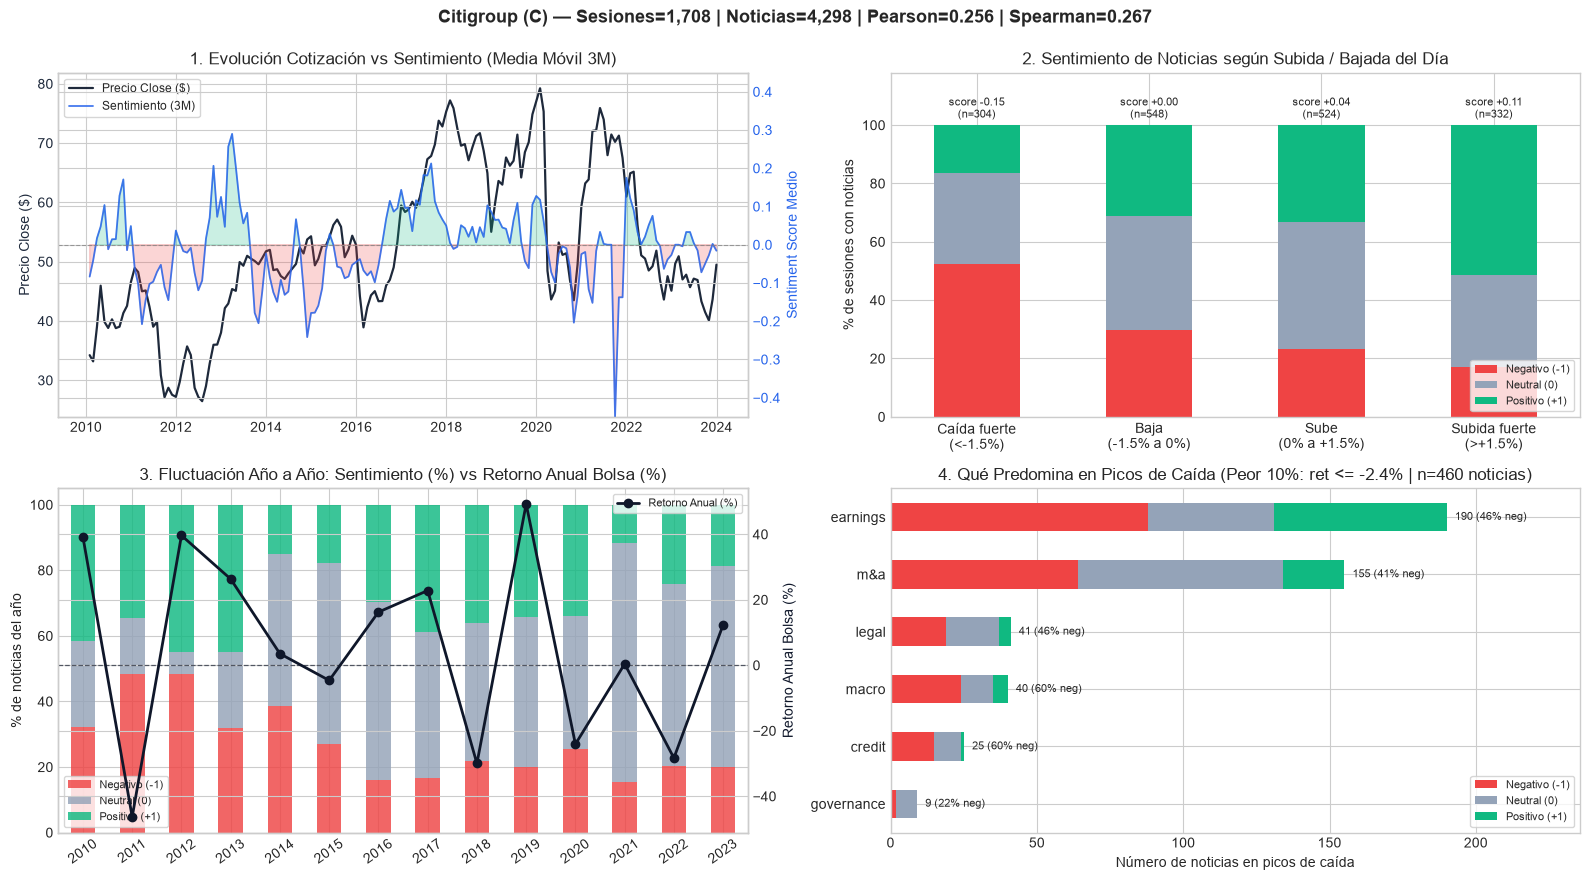

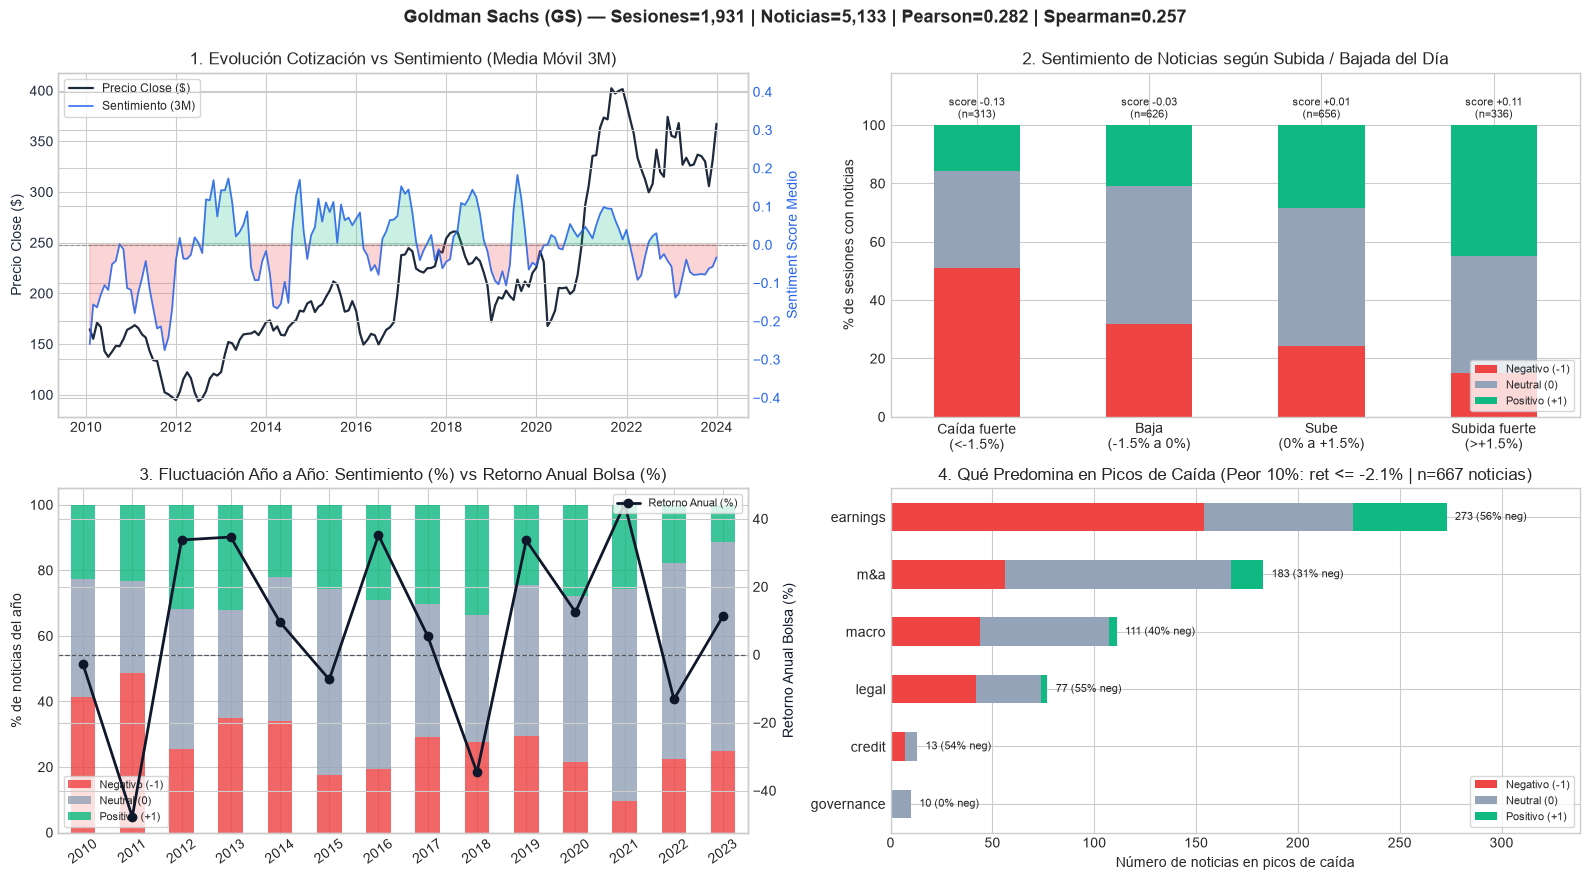

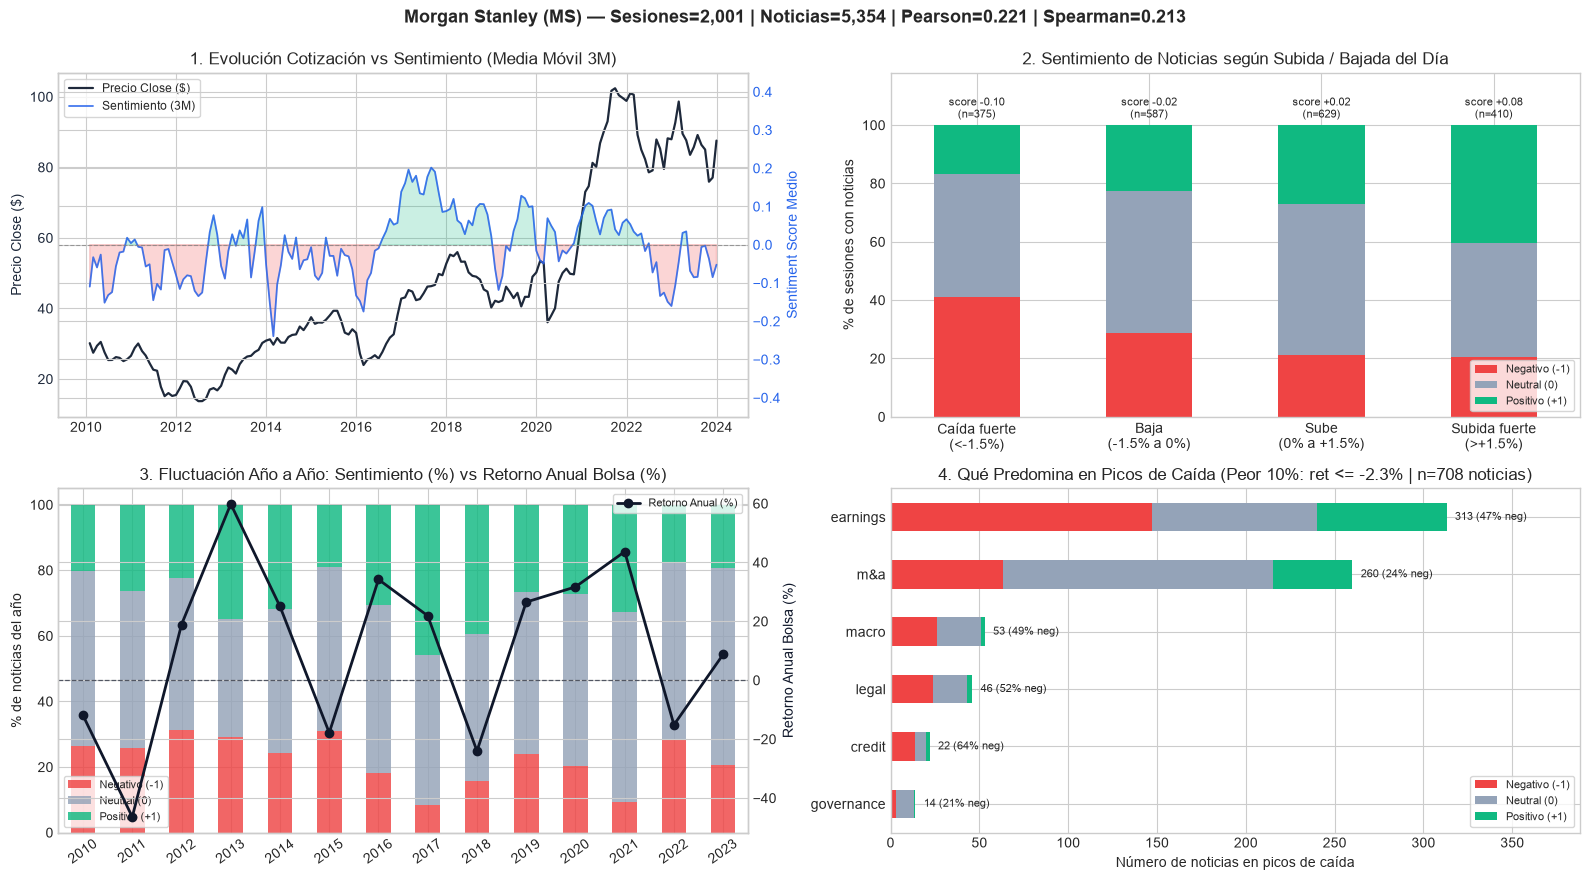

In [52]:
# 5.1 Pasar yfinance de formato ancho a tabla larga (ticker, session_date, retornos)
df_mkt = df_stocks.copy()
df_mkt.index = pd.to_datetime(df_mkt.index).tz_localize(None).normalize().astype("datetime64[ns]")
df_mkt = df_mkt.sort_index()

mkt_partes = []
for tk in TICKETS:
    col_o, col_c = f"Open_{tk}", f"Close_{tk}"
    if col_o in df_mkt.columns and col_c in df_mkt.columns:
        sub_m = pd.DataFrame({
            "session_date": df_mkt.index,
            "ticker": tk,
            "ret_sesion": (df_mkt[col_c] - df_mkt[col_o]) / df_mkt[col_o],
            "ret_diario": df_mkt[col_c].pct_change(),
        })
        sub_m["ret_sig"] = sub_m["ret_diario"].shift(-1)
        mkt_partes.append(sub_m)

df_ret = pd.concat(mkt_partes, ignore_index=True).dropna(subset=["ret_diario"]).sort_values(["session_date", "ticker"])

# 5.2 Alinear cada noticia a la sesión bursátil correspondiente sin look-ahead:
# - premarket / intraday / date_only -> primera sesión hábil desde su día (`>= fecha`)
# - afterhours (>=16:00 ET) -> se desplaza +1 día para alinearse con la apertura/sesión siguiente
df_news_mkt = df_silver.dropna(subset=["datetime"]).copy()
dt_et_col = pd.to_datetime(df_news_mkt["datetime"])
if dt_et_col.dt.tz is not None:
    dt_et_col = dt_et_col.dt.tz_convert("America/New_York").dt.tz_localize(None)
df_news_mkt["news_date"] = dt_et_col.dt.normalize().astype("datetime64[ns]")
if "market_session" in df_news_mkt.columns:
    es_post = df_news_mkt["market_session"] == "afterhours"
    df_news_mkt.loc[es_post, "news_date"] = df_news_mkt.loc[es_post, "news_date"] + pd.Timedelta(days=1)
df_news_mkt = df_news_mkt.sort_values("news_date")

alineado = pd.merge_asof(
    df_news_mkt,
    df_ret.sort_values("session_date"),
    left_on="news_date",
    right_on="session_date",
    by="ticker",
    direction="forward",
).dropna(subset=["ret_diario"])

# Agregación diaria (ticker x session_date) para evitar sobreponderar días con muchas noticias repetidas
diario = (
    alineado.groupby(["ticker", "banco", "session_date"], as_index=False)
    .agg(
        sent_score_medio=("sentiment_score", "mean"),
        sent_label_dom=("sentiment_label", lambda s: int(np.sign(s.mean())) if abs(s.mean()) > 0.15 else 0),
        n_noticias=("record_id", "count"),
        ret_sesion=("ret_sesion", "first"),
        ret_diario=("ret_diario", "first"),
        ret_sig=("ret_sig", "first"),
    )
)

print(f"[OK] Cruce completado: {len(alineado):,} noticias -> {len(diario):,} pares únicos (banco x sesión bursátil).")

# 5.3 Retorno medio en puntos porcentuales (%) según etiqueta dominante del día
res_ret = (
    diario.groupby("sent_label_dom")[["ret_sesion", "ret_diario", "ret_sig"]]
    .agg(["count", "mean"])
)
res_tabla = pd.DataFrame({
    "Sesiones": diario.groupby("sent_label_dom").size(),
    "Ret_Sesión_Media (%)": (diario.groupby("sent_label_dom")["ret_sesion"].mean() * 100).round(3),
    "Ret_Diario_Media (%)": (diario.groupby("sent_label_dom")["ret_diario"].mean() * 100).round(3),
    "Ret_t+1_Media (%)": (diario.groupby("sent_label_dom")["ret_sig"].mean() * 100).round(3),
})
res_tabla.index = [{-1: "Negativo (-1)", 0: "Neutral (0)", 1: "Positivo (+1)"}[i] for i in res_tabla.index]
print("\n=== RETORNO BURSÁTIL MEDIO SEGÚN SENTIMIENTO DIARIO (yfinance) ===")
display(res_tabla)

spread_bps = (diario.loc[diario["sent_label_dom"] == 1, "ret_diario"].mean() - diario.loc[diario["sent_label_dom"] == -1, "ret_diario"].mean()) * 10000
corr_p = diario["sent_score_medio"].corr(diario["ret_diario"], method="pearson")
corr_s = diario["sent_score_medio"].corr(diario["ret_diario"], method="spearman")
print(f"Spread diario (Positivo - Negativo): {spread_bps:+.1f} bps | Pearson={corr_p:.4f} | Spearman={corr_s:.4f}")

# 5.4 Correlación por banco y gráfico
corr_banco = diario.groupby("banco").apply(
    lambda g: pd.Series({
        "Sesiones": len(g),
        "Pearson_Diario": g["sent_score_medio"].corr(g["ret_diario"], method="pearson"),
        "Spearman_Diario": g["sent_score_medio"].corr(g["ret_diario"], method="spearman"),
        "Ret_Pos (%)": 100 * g.loc[g["sent_label_dom"] == 1, "ret_diario"].mean(),
        "Ret_Neg (%)": 100 * g.loc[g["sent_label_dom"] == -1, "ret_diario"].mean(),
    })
).round(4)
display(corr_banco)

# 5.4b Impacto por franja horaria real de Nueva York (UTC -> America/New_York)
# Distinguimos las noticias sin reloj (`00:00:00 UTC`, solo fecha) de las que tienen hora real:
# Premarket (<09:30 ET), Intradía (09:30-16:00 ET) y Post-cierre (>=16:00 ET).
df_mkt_slots = []
for tk in TICKETS:
    o, c = df_mkt[f"Open_{tk}"], df_mkt[f"Close_{tk}"]
    s = pd.DataFrame({
        "session_date": df_mkt.index,
        "ticker": tk,
        "gap_open_t": (o - c.shift(1)) / c.shift(1),
        "ret_t": c.pct_change(),
    })
    s["gap_open_t1"] = (o.shift(-1) - c) / c
    s["ret_t1"] = s["ret_t"].shift(-1)
    df_mkt_slots.append(s)
df_ret_slots = pd.concat(df_mkt_slots).dropna(subset=["ret_t"]).sort_values(["session_date", "ticker"])

df_et = df_silver.dropna(subset=["datetime"]).copy()
dt_et = pd.to_datetime(df_et["datetime"])
if dt_et.dt.tz is None:
    dt_et = dt_et.dt.tz_localize("America/New_York")
else:
    dt_et = dt_et.dt.tz_convert("America/New_York")

es_solo_fecha = (
    ~df_et["has_exact_time"].astype(bool)
    if "has_exact_time" in df_et.columns
    else (dt_et.dt.hour == 0) & (dt_et.dt.minute == 0) & (dt_et.dt.second == 0)
)
mins_et = dt_et.dt.hour * 60 + dt_et.dt.minute

df_et["et_date"] = dt_et.dt.tz_localize(None).dt.normalize().astype("datetime64[ns]")
df_et["franja_et"] = np.where(
    es_solo_fecha,
    "0. Sin hora real (date_only)",
    np.where(
        mins_et < 570,
        "1. Premarket (<09:30 ET)",
        np.where(mins_et < 960, "2. Intradía (09:30-16:00 ET)", "3. Post-cierre (>=16:00 ET)"),
    ),
)

al_et = pd.merge_asof(
    df_et.sort_values("et_date"),
    df_ret_slots,
    left_on="et_date",
    right_on="session_date",
    by="ticker",
    direction="forward",
).dropna(subset=["ret_t"])

filas_et = []
for franja, g in al_et.groupby("franja_et"):
    d_et = g.groupby(["ticker", "session_date"], as_index=False).agg(
        sc=("sentiment_score", "mean"),
        lbl=("sentiment_label", lambda s: int(np.sign(s.mean())) if abs(s.mean()) > 0.15 else 0),
        gap_t=("gap_open_t", "first"),
        ret_t=("ret_t", "first"),
        gap_t1=("gap_open_t1", "first"),
        ret_t1=("ret_t1", "first"),
    )
    pos, neg = d_et[d_et["lbl"] == 1], d_et[d_et["lbl"] == -1]
    filas_et.append({
        "Franja Horaria (ET)": franja,
        "Noticias": len(g),
        "Sesiones": len(d_et),
        "Spread Gap Apertura t (bps)": round((pos["gap_t"].mean() - neg["gap_t"].mean()) * 10000, 1),
        "Spread Retorno Día t (bps)": round((pos["ret_t"].mean() - neg["ret_t"].mean()) * 10000, 1),
        "Spread Gap Mañana t+1 (bps)": round((pos["gap_t1"].mean() - neg["gap_t1"].mean()) * 10000, 1),
        "Spread Retorno Mañana t+1 (bps)": round((pos["ret_t1"].mean() - neg["ret_t1"].mean()) * 10000, 1),
        "Pearson Día t": round(d_et["sc"].corr(d_et["ret_t"]), 4),
    })

print("\n=== IMPACTO SEGÚN FRANJA HORARIA DE NUEVA YORK (Positivo - Negativo en bps) ===")
display(pd.DataFrame(filas_et).sort_values("Franja Horaria (ET)"))

# 5.5 Visualización detallada 2x2 (4 gráficos por banco: Serie 3M, Subidas/Bajadas, Año a Año y Picos de Caída)
tramos_ret = ["Caída fuerte\n(<-1.5%)", "Baja\n(-1.5% a 0%)", "Sube\n(0% a +1.5%)", "Subida fuerte\n(>+1.5%)"]
colores_sent = {-1: "#ef4444", 0: "#94a3b8", 1: "#10b981"}

for tk, info in TICKETS.items():
    banco_nom = info.get("short_name", tk)
    sub_b = diario[diario["ticker"] == tk].copy()
    sub_news = alineado[alineado["ticker"] == tk].copy()
    col_c = f"Close_{tk}"
    if sub_b.empty or col_c not in df_mkt.columns:
        continue

    r_p = sub_b["sent_score_medio"].corr(sub_b["ret_diario"], method="pearson")
    r_s = sub_b["sent_score_medio"].corr(sub_b["ret_diario"], method="spearman")

    precio_m = df_mkt[col_c].resample("ME").mean()
    sent_m = sub_b.set_index("session_date")["sent_score_medio"].resample("ME").mean().rolling(3, min_periods=1).mean()

    fig, axes = plt.subplots(2, 2, figsize=(16, 8.8))
    fig.suptitle(
        f"{banco_nom} ({tk}) — Sesiones={len(sub_b):,} | Noticias={len(sub_news):,} | Pearson={r_p:.3f} | Spearman={r_s:.3f}",
        fontsize=13,
        fontweight="bold",
        y=0.995,
    )

    # 1. Arriba izquierda: Precio mensual vs Sentimiento media móvil 3M
    ax_ts = axes[0, 0]
    l1 = ax_ts.plot(precio_m.index, precio_m.values, color="#1e293b", linewidth=1.6, label="Precio Close ($)")
    ax_ts.set_ylabel("Precio Close ($)", color="#1e293b")
    ax_ts.tick_params(axis="y", labelcolor="#1e293b")
    ax_ts.set_title("1. Evolución Cotización vs Sentimiento (Media Móvil 3M)")

    ax_sent = ax_ts.twinx()
    l2 = ax_sent.plot(sent_m.index, sent_m.values, color="#2563eb", linewidth=1.3, alpha=0.85, label="Sentimiento (3M)")
    ax_sent.fill_between(sent_m.index, sent_m.values, 0, where=(sent_m.values >= 0), color="#10b981", alpha=0.22, interpolate=True)
    ax_sent.fill_between(sent_m.index, sent_m.values, 0, where=(sent_m.values < 0), color="#ef4444", alpha=0.22, interpolate=True)
    ax_sent.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    ax_sent.set_ylabel("Sentiment Score Medio", color="#2563eb")
    ax_sent.tick_params(axis="y", labelcolor="#2563eb")
    ax_sent.set_ylim(-0.45, 0.45)
    lines = l1 + l2
    ax_ts.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=8.5, frameon=True)

    # 2. Arriba derecha: Composición de sentimiento según subida / bajada del día
    ax_bar = axes[0, 1]
    sub_b["tramo_ret"] = pd.cut(sub_b["ret_diario"] * 100, bins=[-100, -1.5, 0.0, 1.5, 100], labels=tramos_ret)
    tab_tramo = pd.crosstab(sub_b["tramo_ret"], sub_b["sent_label_dom"], normalize="index").mul(100)
    for col_lbl in (-1, 0, 1):
        if col_lbl not in tab_tramo.columns:
            tab_tramo[col_lbl] = 0.0
    tab_tramo = tab_tramo.reindex(index=tramos_ret, columns=[-1, 0, 1]).fillna(0.0)

    tab_tramo.rename(columns={-1: "Negativo (-1)", 0: "Neutral (0)", 1: "Positivo (+1)"}).plot(
        kind="bar", stacked=True, color=[colores_sent[-1], colores_sent[0], colores_sent[1]], ax=ax_bar
    )
    scores_tramo = sub_b.groupby("tramo_ret", observed=False)["sent_score_medio"].mean().reindex(tramos_ret)
    counts_tramo = sub_b.groupby("tramo_ret", observed=False).size().reindex(tramos_ret).fillna(0).astype(int)
    for x_i, tr in enumerate(tramos_ret):
        sc = scores_tramo.get(tr, 0.0)
        cnt = counts_tramo.get(tr, 0)
        if pd.notna(sc) and cnt > 0:
            ax_bar.text(x_i, 101.5, f"score {sc:+.2f}\n(n={cnt})", ha="center", va="bottom", fontsize=8)

    ax_bar.set_title("2. Sentimiento de Noticias según Subida / Bajada del Día")
    ax_bar.set_ylabel("% de sesiones con noticias")
    ax_bar.set_xlabel("")
    ax_bar.set_ylim(0, 118)
    ax_bar.tick_params(axis="x", rotation=0)
    ax_bar.legend(loc="lower right", fontsize=8, frameon=True)

    # 3. Abajo izquierda: Fluctuación año a año (Sentimiento % vs Retorno anual en bolsa)
    ax_yr = axes[1, 0]
    sub_news["anio_mkt"] = sub_news["session_date"].dt.year
    tab_yr = pd.crosstab(sub_news["anio_mkt"], sub_news["sentiment_label"], normalize="index").mul(100)
    for col_lbl in (-1, 0, 1):
        if col_lbl not in tab_yr.columns:
            tab_yr[col_lbl] = 0.0
    anios = sorted(tab_yr.index.tolist())
    tab_yr = tab_yr.reindex(index=anios, columns=[-1, 0, 1]).fillna(0.0)
    tab_yr.rename(columns={-1: "Negativo (-1)", 0: "Neutral (0)", 1: "Positivo (+1)"}).plot(
        kind="bar", stacked=True, color=[colores_sent[-1], colores_sent[0], colores_sent[1]], ax=ax_yr, alpha=0.82
    )
    ax_yr.set_title("3. Fluctuación Año a Año: Sentimiento (%) vs Retorno Anual Bolsa (%)")
    ax_yr.set_ylabel("% de noticias del año")
    ax_yr.set_xlabel("")
    ax_yr.set_ylim(0, 105)
    ax_yr.tick_params(axis="x", rotation=35)
    ax_yr.legend(loc="lower left", fontsize=8, frameon=True)

    ret_anual = (
        df_mkt[col_c]
        .groupby(df_mkt.index.year)
        .apply(lambda s: 100.0 * (s.iloc[-1] / s.iloc[0] - 1.0))
        .reindex(anios)
    )
    ax_yr2 = ax_yr.twinx()
    ax_yr2.plot(range(len(anios)), ret_anual.values, color="#0f172a", marker="o", linewidth=2.0, label="Retorno Anual (%)")
    ax_yr2.axhline(0, color="#0f172a", linestyle="--", linewidth=0.9, alpha=0.65)
    ax_yr2.set_ylabel("Retorno Anual Bolsa (%)", color="#0f172a")
    ax_yr2.legend(loc="upper right", fontsize=8, frameon=True)

    # 4. Abajo derecha: Qué predomina en los picos de caídas (peor 10% de sesiones)
    ax_pico = axes[1, 1]
    umbral_pico = sub_b["ret_diario"].quantile(0.10)
    fechas_pico = set(sub_b.loc[sub_b["ret_diario"] <= umbral_pico, "session_date"])
    sub_pico = sub_news[sub_news["session_date"].isin(fechas_pico)]

    tab_pico = pd.crosstab(sub_pico["category"], sub_pico["sentiment_label"])
    for col_lbl in (-1, 0, 1):
        if col_lbl not in tab_pico.columns:
            tab_pico[col_lbl] = 0
    tab_pico = tab_pico[[-1, 0, 1]]
    tab_pico = tab_pico.loc[tab_pico.sum(axis=1).sort_values(ascending=True).index]

    tab_pico.rename(columns={-1: "Negativo (-1)", 0: "Neutral (0)", 1: "Positivo (+1)"}).plot(
        kind="barh", stacked=True, color=[colores_sent[-1], colores_sent[0], colores_sent[1]], ax=ax_pico
    )
    totales_cat = tab_pico.sum(axis=1)
    for y_i, (cat_nom, tot_c) in enumerate(totales_cat.items()):
        pct_neg = 100.0 * tab_pico.loc[cat_nom, -1] / max(tot_c, 1)
        ax_pico.text(tot_c + max(totales_cat.max() * 0.015, 0.5), y_i, f"{tot_c} ({pct_neg:.0f}% neg)", va="center", fontsize=8)

    ax_pico.set_title(
        f"4. Qué Predomina en Picos de Caída (Peor 10%: ret <= {umbral_pico*100:.1f}% | n={len(sub_pico)} noticias)"
    )
    ax_pico.set_xlabel("Número de noticias en picos de caída")
    ax_pico.set_ylabel("")
    ax_pico.set_xlim(0, max(totales_cat.max() * 1.24, 5))
    ax_pico.legend(loc="lower right", fontsize=8, frameon=True)

    plt.tight_layout()
    plt.show()


## 6. Análisis de Costes Reales y Eficiencia del Escalado


In [53]:
# 6.1 Coste real calculado desde los tokens registrados en silver_sentiment_cache.parquet
total_in_tok = float(df_cache["in_tokens"].fillna(0).sum())
total_out_tok = float(df_cache["out_tokens"].fillna(0).sum())

coste_batch_in = (total_in_tok / 1e6) * BATCH_IN_USD_1M
coste_batch_out = (total_out_tok / 1e6) * BATCH_OUT_USD_1M
coste_batch_total = coste_batch_in + coste_batch_out
coste_realtime_total = coste_batch_total * 2.0  # Sin descuento -50% de Batch API

# Ahorro por deduplicación (`input_hash`)
filas_sin_dedup = len(df_silver)
ratio_dedup = 1.0 - (len(df_cache) / max(filas_sin_dedup, 1))
coste_sin_dedup_batch = coste_batch_total * (filas_sin_dedup / max(len(df_cache), 1))

resumen_costes = pd.DataFrame([
    {"Concepto": "Filas Silver cubiertas", "Valor": f"{filas_sin_dedup:,}"},
    {"Concepto": "Llamadas únicas cacheadas (input_hash)", "Valor": f"{len(df_cache):,} (-{ratio_dedup:.1%})"},
    {"Concepto": "Tokens Entrada totales / por noticia", "Valor": f"{total_in_tok:,.0f} ({df_cache['in_tokens'].mean():.1f}/item)"},
    {"Concepto": "Tokens Salida totales / por noticia", "Valor": f"{total_out_tok:,.0f} ({df_cache['out_tokens'].mean():.1f}/item)"},
    {"Concepto": "Coste Real USD (Anthropic Batch -50%)", "Valor": f"${coste_batch_total:.2f}"},
    {"Concepto": "Coste Equivalente USD (Modo Realtime x2)", "Valor": f"${coste_realtime_total:.2f}"},
    {"Concepto": "Ahorro estimado por Batch -50% + Dedup", "Valor": f"${(coste_realtime_total - coste_batch_total) + (coste_sin_dedup_batch - coste_batch_total):.2f}"},
])
display(resumen_costes)


,Concepto,Valor
0,Filas Silver cubiertas,"27,350"
1,Llamadas únicas cacheadas (input_hash),"24,900 (-9.0%)"
2,Tokens Entrada totales / por noticia,"6,972,422 (280.0/item)"
3,Tokens Salida totales / por noticia,"3,748,632 (150.5/item)"
4,Coste Real USD (Anthropic Batch -50%),$1.29
5,Coste Equivalente USD (Modo Realtime x2),$2.57
6,Ahorro estimado por Batch -50% + Dedup,$1.41
